# 09 — Feature engineering (Bab 5.2)

Model (Bab 5.3) adalah **CNN dengan dua input**:

| Input | Asal | Bentuk | Feature engineering |
|---|---|---|---|
| Waveform | `ml/waveforms_z150s` (tidak terstruktur) | 12,000 angka (potongan 120 s) | **Tidak dibuat fitur manual.** CNN mempelajari fiturnya sendiri; di sini hanya ditentukan cara memotong (crop) |
| Konteks | `ml/traces` (terstruktur, dari CSV) | 9 angka | Waktu lokal → sin/cos; jenis sensor → one-hot |

Output: **`/datalake/ml/context`**, 1 baris per rekaman: kunci, label, split, bobot kelas, dan 9 fitur konteks.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../src'))
from common import *
import ml_prep as mp
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pyspark.sql import functions as F

pd.set_option('display.width', 200, 'display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
spark = spark_session('a2_features')
traces = spark.read.parquet(f'{HDFS}{ML}/traces')
win = spark.read.parquet(f'{HDFS}{ML}/waveforms_z150s')

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/09 10:39:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/09 10:39:05 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


## 1. Fitur konteks dari CSV (9 angka)
Waktu mulai rekaman diubah ke waktu lokal Pacific, lalu dipecah menjadi tiga siklus. Alasannya ada di notebook 07: ledakan terjadi siang hari kerja, dan surface event memuncak Juli–September.

| Fitur | Rumus | Alasan |
|---|---|---|
| `hour_sin`, `hour_cos` | jam = jam + menit/60 (14:30 → 14.5); sin/cos(2π · jam / 24) | Siklus harian (ledakan siang hari) |
| `dow_sin`, `dow_cos` | hari = 0 (Senin) … 6 (Minggu); sin/cos(2π · hari / 7) | Siklus mingguan (ledakan jarang di akhir pekan) |
| `doy_sin`, `doy_cos` | hari ke-n dalam tahun (1–366); sin/cos(2π · (n − 1) / 365.25) | Siklus musim (surface event di musim panas) |
| `sensor_EH`, `sensor_BH`, `sensor_HH` | 1 untuk jenis sensornya, 0 untuk lainnya (one-hot) | Jenis sensor memengaruhi bentuk sinyal |

**Kenapa sin dan cos?** Waktu berputar: 23:59 seharusnya dekat dengan 00:00, Minggu dekat Senin, 31 Desember dekat 1 Januari. Sebagai angka biasa (23 vs 0) keduanya tampak jauh. Dengan sin/cos, waktu menjadi titik di lingkaran. Dua angka dibutuhkan karena sin saja memberi nilai yang sama untuk 06:00 dan 18:00.

**Kenapa one-hot untuk sensor?** EH/BH/HH adalah kategori, bukan urutan. Kalau dikodekan 0/1/2, model akan mengira HH "dua kali" EH.

In [2]:
local = F.from_utc_timestamp('trace_start_time', 'America/Los_Angeles')
hour = F.hour(local) + F.minute(local) / 60
dow = (F.dayofweek(local) + 5) % 7
doy = F.dayofyear(local) - 1
cyc = lambda x, period, name: [F.sin(2 * np.pi * x / period).alias(f'{name}_sin'), F.cos(2 * np.pi * x / period).alias(f'{name}_cos')]
ctx = traces.select('dataset', 'trace_name', 'label', 'split', 'class_weight',
                    *cyc(hour, 24, 'hour'), *cyc(dow, 7, 'dow'), *cyc(doy, 365.25, 'doy'),
                    *[(F.col('station_channel_code') == s).cast('double').alias(f'sensor_{s}') for s in ['EH', 'BH', 'HH']])
ctx.coalesce(1).write.mode('overwrite').parquet(f'{HDFS}{ML}/context')
ctx = spark.read.parquet(f'{HDFS}{ML}/context')
ctx.select('label', 'split', *mp.CONTEXT_FEATURES).show(5, truncate=False)

+-----+-----+-------------------+--------------------+------------------+--------------------+-------------------+------------------+---------+---------+---------+
|label|split|hour_sin           |hour_cos            |dow_sin           |dow_cos             |doy_sin            |doy_cos           |sensor_EH|sensor_BH|sensor_HH|
+-----+-----+-------------------+--------------------+------------------+--------------------+-------------------+------------------+---------+---------+---------+
|noise|train|0.8314696123025451 |0.5555702330196024  |-0.433883739117558|-0.9009688679024191 |-0.4051645224207563|0.9142437912130223|0.0      |1.0      |0.0      |
|noise|train|0.8314696123025451 |0.5555702330196024  |-0.433883739117558|-0.9009688679024191 |-0.4051645224207563|0.9142437912130223|0.0      |1.0      |0.0      |
|noise|train|0.8265897491271889 |-0.5628049276950682 |0.9749279121818236|-0.22252093395631434|-0.6383844591746642|0.769717664006921 |1.0      |0.0      |0.0      |
|noise|train|-0.

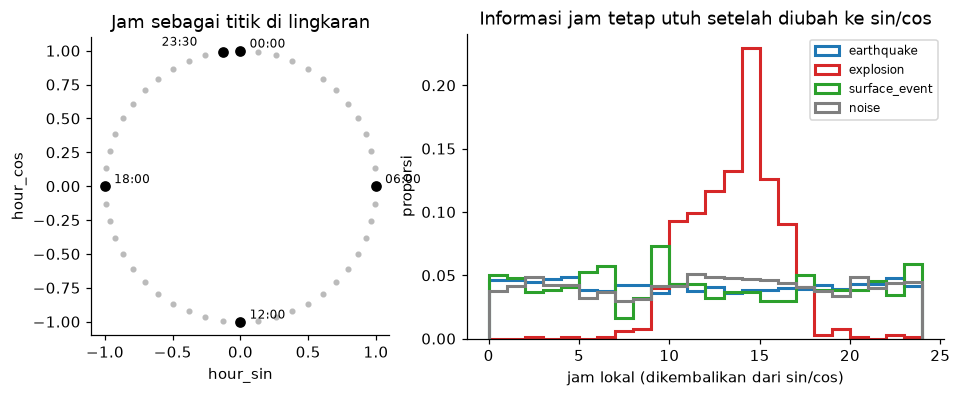

In [3]:
hh = np.arange(0, 24, 0.5)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1, 1.6]})
axes[0].plot(np.sin(2 * np.pi * hh / 24), np.cos(2 * np.pi * hh / 24), 'o', color='#bbbbbb', ms=3)
for h_ in [0, 6, 12, 18, 23.5]:
    x, y = np.sin(2 * np.pi * h_ / 24), np.cos(2 * np.pi * h_ / 24)
    axes[0].plot(x, y, 'o', color='k'); axes[0].annotate(f'{int(h_):02d}:{int(h_ % 1 * 60):02d}', (x, y), xytext=(-40, 4) if h_ == 23.5 else (6, 2), textcoords='offset points', fontsize=8)
axes[0].set(xlabel='hour_sin', ylabel='hour_cos', aspect='equal', title='Jam sebagai titik di lingkaran')
pdc = ctx.select('label', 'hour_sin', 'hour_cos').sample(fraction=0.05, seed=42).toPandas()
pdc['hour'] = (np.degrees(np.arctan2(pdc.hour_sin, pdc.hour_cos)) % 360) / 15
for c in CLASSES:
    v = pdc.loc[pdc.label == c, 'hour']
    axes[1].hist(v, bins=np.arange(0, 24.5, 1), histtype='step', density=True, lw=2, color=COLORS[c], label=c)
axes[1].set(xlabel='jam lokal (dikembalikan dari sin/cos)', ylabel='proporsi', title='Informasi jam tetap utuh setelah diubah ke sin/cos')
axes[1].legend(fontsize=8)
save_fig('a2_context_encoding'); plt.show()

Kiri: 23:30 berada tepat di sebelah 00:00 di lingkaran. Kanan: jam yang dihitung balik dari sin/cos menghasilkan pola yang sama dengan notebook 07 (ledakan memuncak siang hari), jadi **tidak ada informasi yang hilang** karena encoding.

## 2. Waveform: input CNN tanpa fitur manual
Waveform **tidak diringkas menjadi fitur buatan** (durasi, frekuensi, dll.). CNN membaca 12,000 angka langsung:
- **Lapisan konvolusi pertama** = sekumpulan filter kecil yang digeser sepanjang sinyal. Bobotnya dipelajari dari data, sehingga CNN menemukan sendiri pola frekuensi yang berguna (pengganti bandpass filter).
- **Lapisan berikutnya** menggabungkan pola kecil menjadi pola besar: awal kejadian yang tajam, durasi, peredaman.
- **Global average pooling** merangkum seluruh 120 detik menjadi beberapa angka, **tanpa peduli di detik ke-berapa** pola muncul.

**Crop 120 s dari 150 s:**
- **Training:** titik mulai potongan diambil acak antara detik 0 dan 30 (geser ±15 s). Rekaman yang sama terlihat sedikit berbeda setiap epoch, sehingga model tidak bisa menghafal "surface event selalu mulai di detik 70".
- **Validasi & uji:** selalu potongan tengah (detik 15–135), supaya hasil evaluasi sama setiap kali. Potongan ini masih memuat awal kejadian semua rekaman (P paling awal detik 36, paling akhir detik 106).

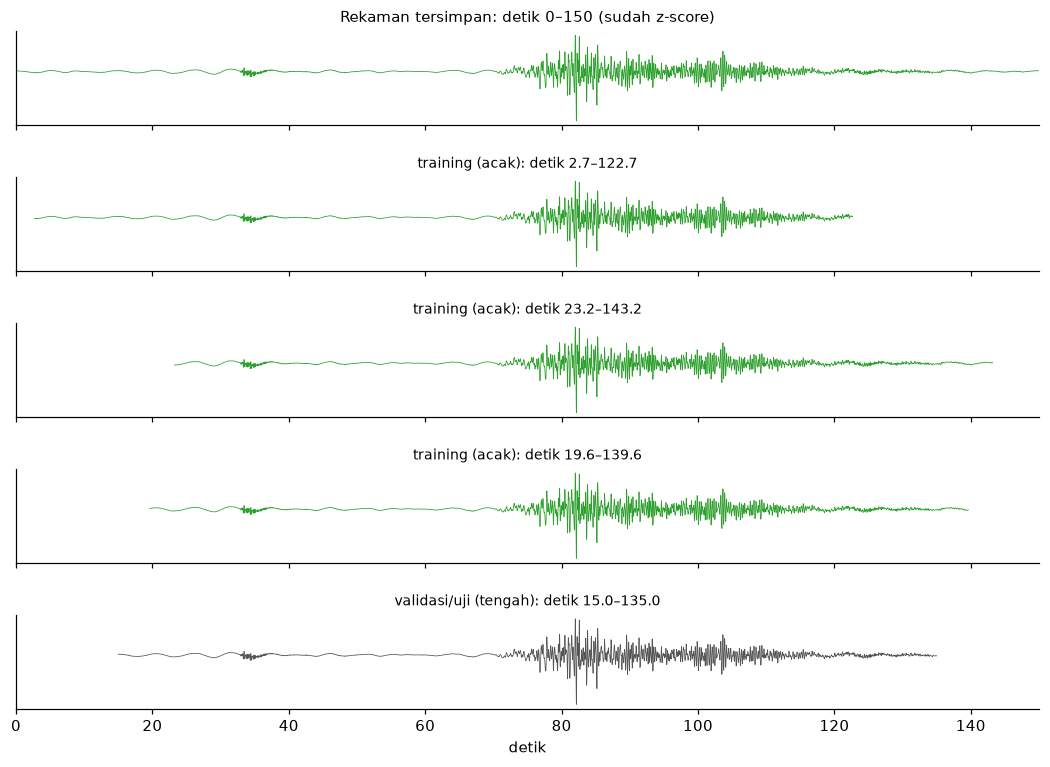

In [4]:
ex = (win.filter("label = 'surface_event' AND split = 'train'").orderBy('trace_name').limit(1)
      .select('trace_name', 'z').toPandas().iloc[0])
x = np.asarray(ex.z)
rng = np.random.default_rng(42)
starts = [int(rng.integers(0, mp.N - mp.CROP + 1)) for _ in range(3)]
fig, axes = plt.subplots(5, 1, figsize=(12, 8), sharex=True, gridspec_kw={'hspace': .55})
axes[0].plot(np.arange(mp.N) / 100, x, color=COLORS['surface_event'], lw=.5)
axes[0].set_title('Rekaman tersimpan: detik 0–150 (sudah z-score)', fontsize=10)
for ax, st, lab in zip(axes[1:], starts + [(mp.N - mp.CROP) // 2], ['training (acak)'] * 3 + ['validasi/uji (tengah)']):
    t = np.arange(st, st + mp.CROP) / 100
    ax.plot(t, x[st:st + mp.CROP], color='#555555' if 'tengah' in lab else COLORS['surface_event'], lw=.5)
    ax.set_title(f'{lab}: detik {st / 100:.1f}–{(st + mp.CROP) / 100:.1f}', fontsize=9)
for ax in axes:
    ax.set_yticks([]); ax.set_xlim(0, 150)
axes[-1].set_xlabel('detik')
save_fig('a2_crop_illustration'); plt.show()

Kejadian yang sama muncul di posisi berbeda pada setiap potongan training, tetapi bentuknya tetap. Inilah yang memaksa CNN mengenali **bentuk**, bukan **posisi**.

## 3. Pemeriksaan input model

In [5]:
feat = np.array(mp.CONTEXT_FEATURES)
stats = ctx.select([F.min(f).alias(f'{f}_min') for f in feat] + [F.max(f).alias(f'{f}_max') for f in feat]
                   + [F.sum(F.col(f).isNull().cast('int')).alias(f'{f}_null') for f in feat]).first().asDict()
check = pd.DataFrame({'min': [stats[f'{f}_min'] for f in feat], 'max': [stats[f'{f}_max'] for f in feat],
                      'null': [stats[f'{f}_null'] for f in feat]}, index=feat).round(3)
assert check['null'].sum() == 0 and check['min'].min() >= -1 and check['max'].max() <= 1
onehot = ctx.select((F.col('sensor_EH') + F.col('sensor_BH') + F.col('sensor_HH')).alias('s')).distinct().collect()
assert [r.s for r in onehot] == [1.0]
assert ctx.count() == win.count() == ctx.join(win.select('dataset', 'trace_name'), ['dataset', 'trace_name']).count()

shape = pd.DataFrame({'input': ['waveform (training & evaluasi)', 'konteks'], 'angka_per_rekaman': [mp.CROP, len(feat)],
                      'rekaman': [win.count(), ctx.count()]})
save_md(check.reset_index(names='feature'), 'a2_context_check', 'Rentang nilai fitur konteks (harus −1…1, tanpa null)')
save_md(shape, 'a2_model_inputs', 'Bentuk input CNN')
display(shape)
check

,input,angka_per_rekaman,rekaman
0,waveform (training & evaluasi),12000,234467
1,konteks,9,234467


,min,max,null
hour_sin,-1.000,1.000,0
hour_cos,-1.000,1.000,0
dow_sin,-0.975,0.975,0
dow_cos,-0.901,1.000,0
doy_sin,-1.000,1.000,0
doy_cos,-1.000,1.000,0
sensor_EH,0.000,1.000,0
sensor_BH,0.000,1.000,0
sensor_HH,0.000,1.000,0


- 9 fitur konteks: semua bernilai −1…1, tanpa nilai kosong, dan setiap rekaman tepat punya satu jenis sensor.
- Setiap rekaman di tabel konteks punya pasangan waveform (dan sebaliknya).
- Input siap untuk CNN (Bab 5.3): **12,000 angka waveform + 9 angka konteks → 4 kelas**.

In [6]:
spark.stop()